# Exploratory Data Analysis (EDA): South African Education Dataset

**Dataset:** `School_Data_CSV.csv`  
**Stage:** 1 — Understand the dataset, variable types, preparation requirements, and potential data-quality issues.

## Objectives
1. Load the CSV safely and inspect its structure.
2. Understand each variable and its likely role.
3. Assess missing values, duplicates, uniqueness, inconsistent categories, and mixed data types.
4. Validate coordinate fields and inspect distributions.
5. Record preparation recommendations without silently deleting or changing source records.

> **Important:** This notebook is diagnostic. It preserves the raw data in `df_raw` and creates a separate working copy for checks. Do not remove duplicates or impute missing values until their meaning has been investigated.


## 1. Algorithm / workflow

**Input:** CSV file containing South African education records.  
**Output:** A structured EDA report, diagnostic tables, plots, and preparation recommendations.

1. Import analysis libraries.
2. Load the CSV using a suitable text encoding.
3. Display the number of rows and columns, column names, sample records, and inferred data types.
4. Review the meaning and expected type of each variable.
5. Calculate missing-value counts and percentages.
6. Inspect unique values and category consistency for identifier and categorical columns.
7. Check full-row duplicates and repeated identifiers.
8. Convert coordinate columns in a separate working copy to numeric values and flag invalid/out-of-range coordinates.
9. Generate descriptive statistics and visualisations.
10. Summarise findings and recommend preparation steps for the next stage.

### Pseudocode

```text
START
  Import pandas, numpy, matplotlib and seaborn
  Read CSV with encoding fallback
  Save original dataset as df_raw
  Display shape, columns, sample rows and data types
  For each column:
      calculate missing count and percentage
      inspect unique values and inferred role
  Check exact duplicate rows
  Check repeated identifier values
  Create a working copy
  Convert longitude and latitude to numeric in working copy
  Flag invalid coordinates and unusual category values
  Plot missingness and key variable distributions
  Summarise data-quality risks and preparation recommendations
STOP
```


In [1]:
# 2. Import libraries

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

# Change this path if the CSV is stored elsewhere.
FILE_PATH = Path("School_Data_CSV.csv")


## 3. Load the CSV file

The supplied file may use a Windows-style encoding rather than UTF-8. The loader below tries common encodings and reports which one worked. If the file is in another folder, update `FILE_PATH`.


In [2]:
def load_csv_with_encoding_fallback(file_path):
    """Load a CSV using common encodings; raise a helpful error if all fail."""
    encodings = ["utf-8", "utf-8-sig", "cp1252", "latin1"]
    errors = {}

    for encoding in encodings:
        try:
            data = pd.read_csv(file_path, encoding=encoding, low_memory=False)
            print(f"Loaded successfully using encoding: {encoding}")
            return data
        except UnicodeDecodeError as exc:
            errors[encoding] = str(exc)

    raise UnicodeError(
        "Could not decode the CSV using the attempted encodings. "
        f"Errors: {errors}"
    )

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {FILE_PATH.resolve()}. Put the CSV in the same folder "
        "as this notebook or update FILE_PATH."
    )

df_raw = load_csv_with_encoding_fallback(FILE_PATH)
df = df_raw.copy(deep=True)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())


Loaded successfully using encoding: cp1252
Rows: 199,853
Columns: 9


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


## 4. Dataset structure and variable types

Pandas' inferred type is not necessarily the correct analytical type. For example, school codes and ward identifiers may look numeric but should usually remain identifiers (strings), not measurements.


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nPandas-inferred data types:")
display(df.dtypes.rename("inferred_dtype").to_frame())

print("\\nDataset information:")
df.info()

print("\\nNumeric summary:")
display(df.describe(include=[np.number]).T)

print("\\nSummary of all columns:")
display(df.describe(include="all").T)


Column names:
['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat']
\nPandas-inferred data types:


,inferred_dtype
emisno,str
centername,str
institution_name,str
centreno,str
quintile,str
ward_id,str
street_address,str
new_long,str
new_lat,float64


\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 199853 entries, 0 to 199852
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   emisno            199853 non-null  str    
 1   centername        193922 non-null  str    
 2   institution_name  133926 non-null  str    
 3   centreno          199823 non-null  str    
 4   quintile          197040 non-null  str    
 5   ward_id           199071 non-null  str    
 6   street_address    193150 non-null  str    
 7   new_long          167741 non-null  str    
 8   new_lat           84107 non-null   float64
dtypes: float64(1), str(8)
memory usage: 13.7 MB
\nNumeric summary:


,count,mean,std,min,25%,50%,75%,max
new_lat,84107.0,-1784.735646,227813.390158,-30556799.0,-30.99605,-28.6447,-26.146448,33.994485


\nSummary of all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
emisno,199853,33670,99,1550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
centername,193922,12063,NOT APPLICABLE,90058,NaN,NaN,NaN,NaN,NaN,NaN,NaN
institution_name,133926,51343,HLANGANANI SECONDARY SCHOOL,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
centreno,199823,10359,99,95552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quintile,197040,23,1,49010,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ward_id,199071,4857,TO BE UPDATED,12074,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street_address,193150,51328,.,1760,NaN,NaN,NaN,NaN,NaN,NaN,NaN
new_long,167741,57215,TRUE,5677,NaN,NaN,NaN,NaN,NaN,NaN,NaN
new_lat,84107.0,NaN,NaN,NaN,-1784.735646,227813.390158,-30556799.0,-30.99605,-28.6447,-26.146448,33.994485


In [4]:
# Variable dictionary: initial interpretation based on column names.
# Confirm these meanings with the dataset's official metadata/data dictionary.

variable_dictionary = pd.DataFrame([
    ["emisno", "Identifier (string)", "Education management information identifier", "Check missingness, uniqueness, leading zeros, and repeated IDs"],
    ["centername", "Categorical text", "Education centre name", "Check blanks, whitespace, spelling variants, and duplicates"],
    ["institution_name", "Categorical text", "Institution name", "Check missingness and possible alternative names"],
    ["centreno", "Identifier (string)", "Centre identifier", "Check missingness, uniqueness, and repeated IDs"],
    ["quintile", "Ordinal categorical", "School quintile/classification", "Check expected categories and variants such as Q1 vs 1"],
    ["ward_id", "Identifier (string)", "Geographic ward code", "Preserve as an identifier; check missing and malformed codes"],
    ["street_address", "Text", "Street address", "Check missingness and formatting"],
    ["new_long", "Numeric coordinate", "Longitude", "Convert to numeric and validate geographic bounds"],
    ["new_lat", "Numeric coordinate", "Latitude", "Convert to numeric and validate geographic bounds"],
], columns=["column", "expected_role_or_type", "likely_meaning", "preparation_checks"])

display(variable_dictionary)


,column,expected_role_or_type,likely_meaning,preparation_checks
0,emisno,Identifier (string),Education management information identifier,"Check missingness, uniqueness, leading zeros, and repeated IDs"
1,centername,Categorical text,Education centre name,"Check blanks, whitespace, spelling variants, and duplicates"
2,institution_name,Categorical text,Institution name,Check missingness and possible alternative names
3,centreno,Identifier (string),Centre identifier,"Check missingness, uniqueness, and repeated IDs"
4,quintile,Ordinal categorical,School quintile/classification,Check expected categories and variants such as Q1 vs 1
5,ward_id,Identifier (string),Geographic ward code,Preserve as an identifier; check missing and malformed codes
6,street_address,Text,Street address,Check missingness and formatting
7,new_long,Numeric coordinate,Longitude,Convert to numeric and validate geographic bounds
8,new_lat,Numeric coordinate,Latitude,Convert to numeric and validate geographic bounds


## 5. Missing-value analysis

Missing values are assessed as both counts and percentages. A high percentage does not automatically mean a column should be dropped: for example, location coordinates may be essential for mapping but irrelevant to a name-based count. Investigate whether missingness is concentrated in particular school types, quintiles, provinces, or other groups if those variables are available.


,missing_count,missing_percent,non_missing_count,distinct_non_missing_values
new_lat,115746,57.92,84107,54847
institution_name,65927,32.99,133926,51343
new_long,32112,16.07,167741,57215
street_address,6703,3.35,193150,51328
centername,5931,2.97,193922,12063
quintile,2813,1.41,197040,23
ward_id,782,0.39,199071,4857
centreno,30,0.02,199823,10359
emisno,0,0.00,199853,33670


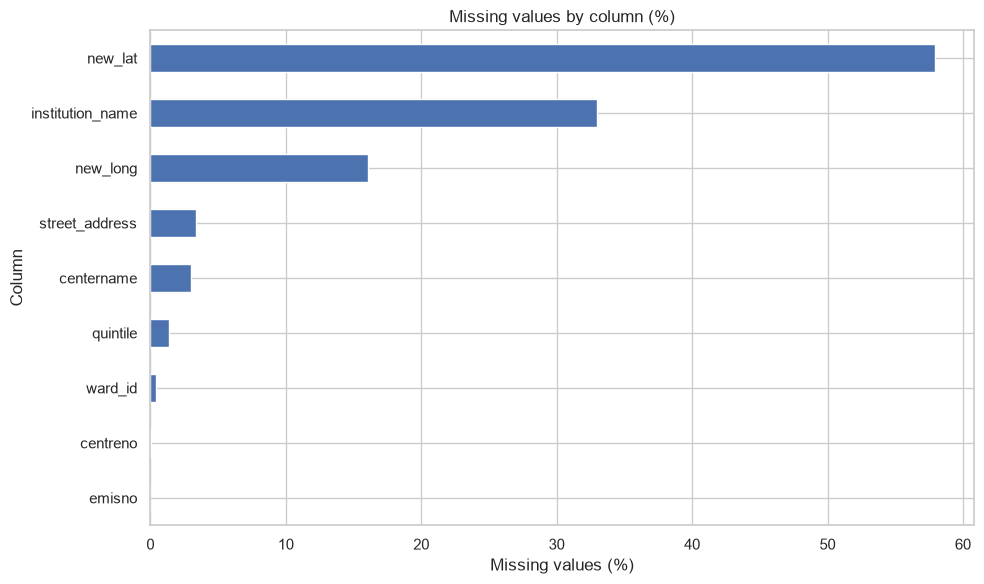

In [5]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "non_missing_count": df.notna().sum(),
    "distinct_non_missing_values": df.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

ax = missing_summary["missing_percent"].sort_values().plot(
    kind="barh", figsize=(10, 6), title="Missing values by column (%)"
)
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
plt.tight_layout()
plt.show()


## 6. Duplicate records and identifier checks

Repeated identifier values are not necessarily errors. One school may legitimately appear in more than one record, depending on how the source was assembled. Compare duplicate rows and identifiers before removing anything.


In [6]:
duplicate_report = pd.DataFrame({
    "check": [
        "Exact duplicate rows",
        "Rows with repeated emisno (excluding missing)",
        "Rows with repeated centreno (excluding missing)",
        "Distinct non-missing emisno values",
        "Distinct non-missing centreno values",
    ],
    "count": [
        int(df.duplicated().sum()),
        int(df["emisno"].duplicated(keep=False).sum()) if "emisno" in df else np.nan,
        int(df["centreno"].duplicated(keep=False).sum()) if "centreno" in df else np.nan,
        int(df["emisno"].nunique(dropna=True)) if "emisno" in df else np.nan,
        int(df["centreno"].nunique(dropna=True)) if "centreno" in df else np.nan,
    ]
})

display(duplicate_report)

# Inspect examples rather than deleting repeated records.
if "emisno" in df.columns:
    repeated_emisno = df[df["emisno"].notna() & df["emisno"].duplicated(keep=False)]
    print("Example records with repeated emisno values:")
    display(repeated_emisno.sort_values("emisno").head(20))

print("Example exact duplicate rows:")
display(df[df.duplicated(keep=False)].head(20))


,check,count
0,Exact duplicate rows,799
1,Rows with repeated emisno (excluding missing),198084
2,Rows with repeated centreno (excluding missing),199648
3,Distinct non-missing emisno values,33670
4,Distinct non-missing centreno values,10359


Example records with repeated emisno values:


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
111020,100000001,NOT APPLICABLE,NaN,99,NOT APPLICABLE,85,"19648 MXOLISI STREET,NOMZAMO,STRAND,7140",18.855764,-34.115402
138985,100000001,NOT APPLICABLE,NaN,99,TO BE UPDATED,85,"19648 MXOLISI STREET,NOMZAMO,STRAND,7140",18.855764,-34.115402
111198,100000002,NOT APPLICABLE,NaN,99,NOT APPLICABLE,89,"82 CWANGO STREET,KHAYELITSHA-SITE C,KHAYELITSHA,",18.654099,-34.013768
138986,100000002,NOT APPLICABLE,NaN,99,TO BE UPDATED,89,"82 CWANGO STREET,KHAYELITSHA-SITE C,KHAYELITSHA,",18.654099,-34.013768
111154,100000003,NOT APPLICABLE,NaN,99,NOT APPLICABLE,5,"10 DRIEKOPPEN ROAD,EDGEMEAD,GOODWOOD,7441",18.550712,-33.866566
138987,100000003,NOT APPLICABLE,NaN,99,TO BE UPDATED,5,"10 DRIEKOPPEN ROAD,EDGEMEAD,GOODWOOD,7441",18.550712,-33.866566
111086,100000004,NOT APPLICABLE,NaN,99,NOT APPLICABLE,93,"48577 CELEKWANE STREET,KHAYELITSHA,",18.676659,-34.026973
138988,100000004,NOT APPLICABLE,NaN,99,TO BE UPDATED,93,"48577 CELEKWANE STREET,KHAYELITSHA,",18.676659,-34.026973
110797,100000005,NOT APPLICABLE,NaN,99,NOT APPLICABLE,8,"2 ALBANIE STREET,MALMESBURY,",18.722713,-33.466470
138989,100000005,NOT APPLICABLE,NaN,99,TO BE UPDATED,8,"2 ALBANIE STREET,MALMESBURY,",18.722713,-33.466470


Example exact duplicate rows:


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
10332,700111112,NALEDI SECONDARY SCHOOL,NALEDI SECONDARY SCHOOL,8111112,4,79800020,"378 NAPE, NALEDI, SOWETO, 1867",27.83081497,NaN
10339,700111195,PRUDENS SECONDARY SCHOOL,PRUDENS SECONDARY SCHOOL,8111195,3,79800021,"636 LEGWALE, TLADI, SOWETO, 1868",27.84465333,NaN
10340,700111203,REASOMA SECONDARY SCHOOL,REASOMA SECONDARY SCHOOL,8111203,5,79800014,"2001 NTLOKO STREET, PROTEA GLEN, SOWETO, 1818",27.83656,NaN
10344,700111252,SEKANONTOANE SECONDARY SCHOOL,SEKANONTOANE SECONDARY SCHOOL,8111252,4,79800015,"1926 MABALANE STREET, SENAOANE, SOWETO, 1818",27.86290833,NaN
10345,700111260,SENAOANE SECONDARY SCHOOL,SENAOANE SECONDARY SCHOOL,8111260,4,79800015,"1105 UMKHONDO STREET, SOWETO, SOWETO, 1818",27.86721833,NaN
10348,700111328,TETELO SECONDARY SCHOOL,TETELO SECONDARY SCHOOL,8111328,5,79800014,"1027 LETSATSI RADEBE STREET, PROTEA NORTH, SOWETO, 1860",27.829535,NaN
10358,700111450,VUWANI SECONDARY SCHOOL,VUWANI SECONDARY SCHOOL,8111450,3,79800012,"3346 FUNDUDZI, TSHIAWELO, SOWETO, 1818",27.85554833,NaN
10386,700120097,ELDORADO PARK SECONDARY SCHOOL,ELDORADO PARK SECONDARY SCHOOL,8120097,4,79800017,"1 TURF AVENIUE, ELDORADO PARK, KLIPTOWN, 1812",27.90175333,NaN
10402,700120303,SILVER OAKS SECONDARY SCHOOL,SILVER OAKS SECONDARY SCHOOL,8120303,4,79800018,"4 HEERENGRACHT CRESCENT, ELDORADO PARK EXT 4, JOHANNESBURG, 1812",27.91681167,NaN
10404,700120386,WILLOW CRESCENT SECONDARY SCHOOL,WILLOW CRESCENT SECONDARY SCHOOL,8120386,4,79800018,"451 CNR WILLOW CRESCENT SINGLE, ELDORADO PARK, ELDORADO PARK, 1813",27.91118,NaN


## 7. Inspect categorical values and consistency

This section identifies values that may need standardisation. Do not automatically merge values until the data dictionary confirms that they mean the same thing.


In [7]:
categorical_candidates = [
    col for col in ["quintile", "centername", "institution_name", "ward_id"]
    if col in df.columns
]

for col in categorical_candidates:
    print(f"\\n--- {col} ---")
    print(f"Distinct non-missing values: {df[col].nunique(dropna=True):,}")
    print("Most frequent values (including missing):")
    display(df[col].value_counts(dropna=False).head(25).rename("count").to_frame())

# Focused check for quintile labels
if "quintile" in df.columns:
    quintile_clean_view = (
        df["quintile"]
        .astype("string")
        .str.strip()
        .value_counts(dropna=False)
        .rename_axis("quintile_value")
        .reset_index(name="count")
    )
    display(quintile_clean_view)


\n--- quintile ---
Distinct non-missing values: 23
Most frequent values (including missing):


,count
quintile,
1,49010
2,40114
3,32288
TO BE UPDATED,22300
NOT APPLICABLE,16049
5,12916
4,11429
Q1,3760
Q2,3211


\n--- centername ---
Distinct non-missing values: 12,063
Most frequent values (including missing):


,count
centername,
NOT APPLICABLE,90058
.,35644
TO BE UPDATED,8254
NaN,5931
UNKOWN,1136
NGWAABE,23
LEAP SCIENCE AND MATHS SCHOOL,21
SAKHISIZWE HIGH SCHOOL,20
GREENPOINT SECONDARY SCHOOL,19


\n--- institution_name ---
Distinct non-missing values: 51,343
Most frequent values (including missing):


,count
institution_name,
NaN,65927
HLANGANANI SECONDARY SCHOOL,23
LEAP SCIENCE AND MATHS SCHOOL,19
ZAKHELE PRIMARY SCHOOL,19
SIYABONGA SECONDARY SCHOOL,19
BUYANI PRIMARY SCHOOL,18
JABULANI PRIMARY SCHOOL,18
TEMBENI SENIOR PRIMARY SCHOOL,17
THOLULWAZI SECONDARY SCHOOL,17


\n--- ward_id ---
Distinct non-missing values: 4,857
Most frequent values (including missing):


,count
ward_id,
TO BE UPDATED,12074
99,3661
.,3482
3,1033
6,818
NaN,782
7,750
2,737
4,730


,quintile_value,count
0,1,49010
1,2,40114
2,3,32288
3,TO BE UPDATED,22300
4,NOT APPLICABLE,16049
5,5,12916
6,4,11429
7,Q1,3760
8,Q2,3211
9,Q3,2961


## 8. Data type preparation checks for coordinates

Coordinates are measurements, unlike school and ward identifiers. This section creates a working copy with numeric coordinate columns while preserving `df_raw` unchanged.

The bounding box below is a **broad plausibility check** for South Africa, not a definitive test of whether a school is correctly geocoded. Confirm the appropriate bounds for the study area before using them in analysis.


In [8]:
df_work = df_raw.copy(deep=True)

coordinate_columns = [col for col in ["new_long", "new_lat"] if col in df_work.columns]
for col in coordinate_columns:
    original_non_missing = df_work[col].notna()
    df_work[col] = pd.to_numeric(df_work[col], errors="coerce")
    newly_unparseable = original_non_missing & df_work[col].isna()
    print(f"{col}: {newly_unparseable.sum():,} non-missing values could not be converted to numbers")

if {"new_long", "new_lat"}.issubset(df_work.columns):
    # Broad bounds for South Africa; inspect outliers rather than deleting them.
    longitude_ok = df_work["new_long"].between(16, 34, inclusive="both")
    latitude_ok = df_work["new_lat"].between(-36, -22, inclusive="both")
    both_present = df_work["new_long"].notna() & df_work["new_lat"].notna()
    coordinate_valid = longitude_ok & latitude_ok

    coordinate_report = pd.DataFrame({
        "measure": [
            "Rows with both coordinates present",
            "Rows with at least one coordinate missing",
            "Rows with both coordinates present and within broad South African bounds",
        ],
        "count": [
            int(both_present.sum()),
            int((~both_present).sum()),
            int((both_present & coordinate_valid).sum()),
        ]
    })
    display(coordinate_report)

    suspicious_coordinates = df_work.loc[
        both_present & ~coordinate_valid,
        [c for c in ["emisno", "centername", "street_address", "new_long", "new_lat"] if c in df_work.columns]
    ]
    print("Examples of coordinate pairs outside the broad check:")
    display(suspicious_coordinates.head(20))

    print("Coordinate summary:")
    display(df_work[["new_long", "new_lat"]].describe().T)


new_long: 7,261 non-missing values could not be converted to numbers
new_lat: 0 non-missing values could not be converted to numbers


,measure,count
0,Rows with both coordinates present,84105
1,Rows with at least one coordinate missing,115748
2,Rows with both coordinates present and within broad South African bounds,84090


Examples of coordinate pairs outside the broad check:


,emisno,centername,street_address,new_long,new_lat
81216,600977,TBU,TBU,0.000000e+00,0.000000e+00
81578,404035,NOT APPLICABLE,"NYATI ADMINISTRATIVE AREA, LUSIKISIKI",0.000000e+00,0.000000e+00
92970,400525,NOT APPLICABLE,NaN,2.812528e+06,-2.541703e+01
96000,500327707,NOT APPLICABLE,"487 CHURCH STREET,PIETERMARITZBURG,3202",3.037024e+01,-2.960950e+07
98583,500400562,PINEHILL PRIVATE SCHOOL,"PINETOWN,ALEXANDER PARK,,3610",3.083418e+01,-2.981581e+07
98789,500321937,NOT APPLICABLE,GINGINDLOVU3800,3.158071e+01,-2.902640e+07
103797,996602106,ST THOMAS COMBINED S,"1 FARM,,LEEUWVALLEI,BURGERSFORT,1120",2.985094e+01,-2.184174e+01
106019,800031401,NOT APPLICABLE,"PHOSAVILLE,,1320",2.293813e+01,-3.055680e+07
111676,300017003,NOT APPLICABLE,"1 TH STREET,HOMEVALE,KIMBERLEY,8301",2.472972e+01,-2.869364e+07
113442,107007988,NOT APPLICABLE,NaN,1.869012e+01,3.399448e+01


Coordinate summary:


,count,mean,std,min,25%,50%,75%,max
new_long,160480.0,-207.706471,29773.742748,-2950000.0,27.36819,28.87848,30.423170,2.812528e+06
new_lat,84107.0,-1784.735646,227813.390158,-30556799.0,-30.99605,-28.64470,-26.146448,3.399448e+01


## 9. Distribution and relationship visualisations

These visualisations help reveal common values and possible anomalies. They should be interpreted in the context of how the dataset was collected.


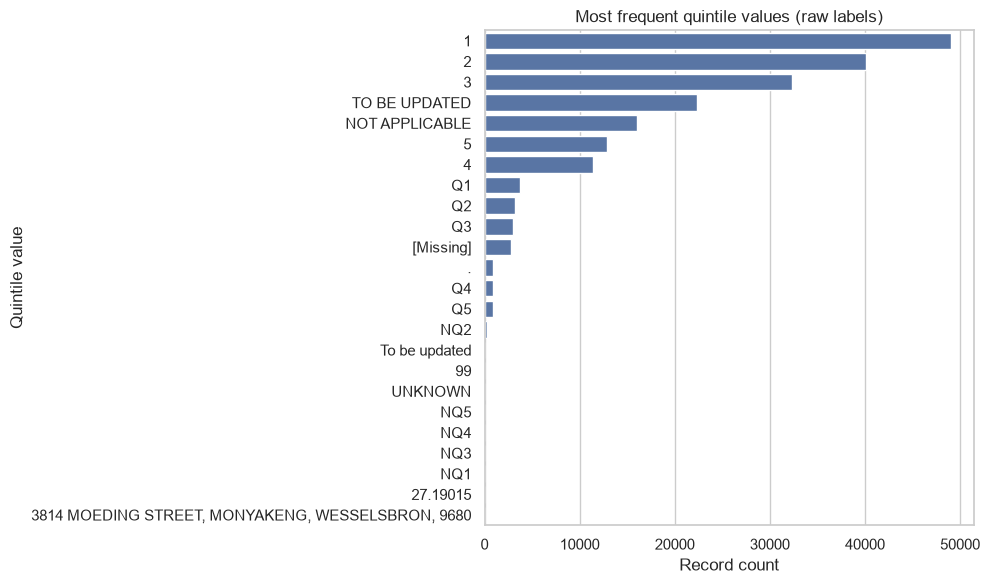

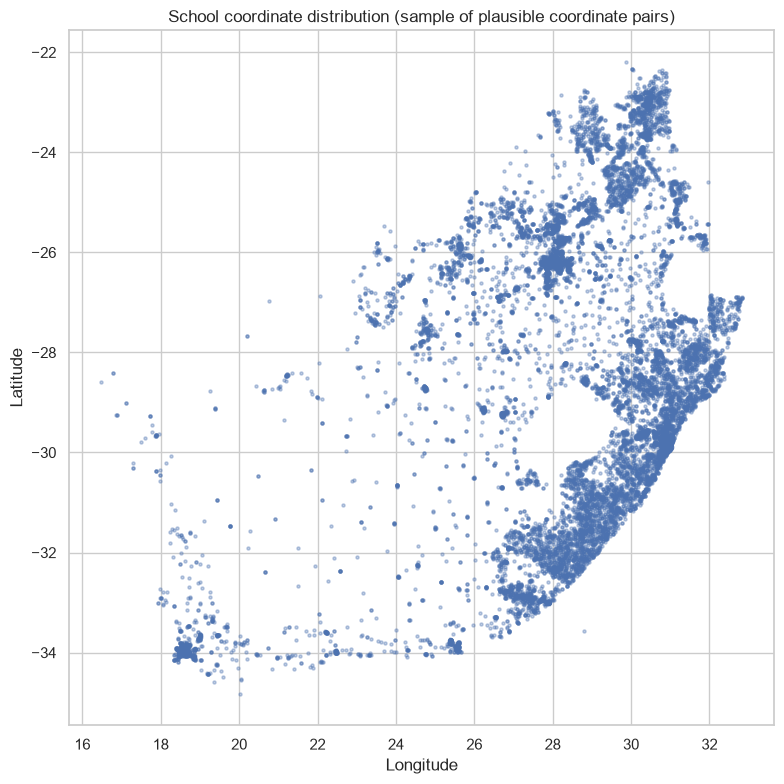

,count,mean,std,min,25%,50%,75%,max
new_long,160480.0,-207.706471,29773.742748,-2950000.0,27.36819,28.87848,30.423170,2.812528e+06
new_lat,84107.0,-1784.735646,227813.390158,-30556799.0,-30.99605,-28.64470,-26.146448,3.399448e+01


In [9]:
# Quintile distribution, including non-standard labels and missing values
if "quintile" in df.columns:
    quintile_counts = df["quintile"].fillna("[Missing]").astype(str).value_counts().head(30)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=quintile_counts.values, y=quintile_counts.index)
    plt.title("Most frequent quintile values (raw labels)")
    plt.xlabel("Record count")
    plt.ylabel("Quintile value")
    plt.tight_layout()
    plt.show()

# Coordinate scatterplot of records with valid broad bounds
if {"new_long", "new_lat"}.issubset(df_work.columns):
    valid_geo = (
        df_work["new_long"].between(16, 34) &
        df_work["new_lat"].between(-36, -22)
    )
    plot_data = df_work.loc[valid_geo, ["new_long", "new_lat"]].dropna()

    if not plot_data.empty:
        # Sample for readability and performance if the dataset is large.
        plot_data = plot_data.sample(n=min(15000, len(plot_data)), random_state=42)
        plt.figure(figsize=(8, 8))
        plt.scatter(plot_data["new_long"], plot_data["new_lat"], s=5, alpha=0.35)
        plt.title("School coordinate distribution (sample of plausible coordinate pairs)")
        plt.xlabel("Longitude")
        plt.ylabel("Latitude")
        plt.tight_layout()
        plt.show()

# Numeric distributions, if other numeric columns exist
numeric_cols = df_work.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    display(df_work[numeric_cols].describe().T)


## 10. Automated data-quality flags

The following table creates a first-pass checklist. It is not a final judgement about the dataset; it highlights areas requiring investigation.


In [10]:
quality_flags = []

def add_flag(issue, count, severity, recommended_action):
    quality_flags.append({
        "issue": issue,
        "records_or_values_affected": int(count),
        "priority": severity,
        "recommended_action": recommended_action
    })

for col in df.columns:
    missing_count = int(df[col].isna().sum())
    if missing_count:
        pct = df[col].isna().mean() * 100
        priority = "High" if pct >= 20 else ("Medium" if pct >= 5 else "Low")
        add_flag(
            f"Missing values in {col} ({pct:.1f}%)",
            missing_count,
            priority,
            "Investigate why values are missing; choose handling based on the intended analysis."
        )

add_flag(
    "Exact duplicate rows",
    int(df.duplicated().sum()),
    "Medium",
    "Compare duplicate records and source rules before deciding whether any should be removed."
)

if "quintile" in df.columns:
    quintile_text = df["quintile"].astype("string").str.strip().str.upper()
    standard_quintiles = {"1", "2", "3", "4", "5", "Q1", "Q2", "Q3", "Q4", "Q5"}
    nonstandard = df["quintile"].notna() & ~quintile_text.isin(standard_quintiles)
    add_flag(
        "Potentially non-standard quintile labels",
        int(nonstandard.sum()),
        "High",
        "Review values such as 'TO BE UPDATED', 'NOT APPLICABLE', '.', and 'UNKNOWN'; confirm official category rules."
    )

if {"new_long", "new_lat"}.issubset(df_work.columns):
    both = df_work["new_long"].notna() & df_work["new_lat"].notna()
    outside = both & ~(
        df_work["new_long"].between(16, 34) &
        df_work["new_lat"].between(-36, -22)
    )
    add_flag(
        "Coordinate pairs outside broad South African bounds",
        int(outside.sum()),
        "High",
        "Verify coordinate reference system, swapped columns, and geocoding quality before mapping."
    )

quality_flags_df = pd.DataFrame(quality_flags).sort_values(
    ["priority", "records_or_values_affected"],
    ascending=[True, False]
)
display(quality_flags_df)


,issue,records_or_values_affected,priority,recommended_action
7,Missing values in new_lat (57.9%),115746,High,Investigate why values are missing; choose handling based on the intended analysis.
1,Missing values in institution_name (33.0%),65927,High,Investigate why values are missing; choose handling based on the intended analysis.
9,Potentially non-standard quintile labels,39636,High,"Review values such as 'TO BE UPDATED', 'NOT APPLICABLE', '.', and 'UNKNOWN'; confirm official ca..."
10,Coordinate pairs outside broad South African bounds,15,High,"Verify coordinate reference system, swapped columns, and geocoding quality before mapping."
5,Missing values in street_address (3.4%),6703,Low,Investigate why values are missing; choose handling based on the intended analysis.
0,Missing values in centername (3.0%),5931,Low,Investigate why values are missing; choose handling based on the intended analysis.
3,Missing values in quintile (1.4%),2813,Low,Investigate why values are missing; choose handling based on the intended analysis.
4,Missing values in ward_id (0.4%),782,Low,Investigate why values are missing; choose handling based on the intended analysis.
2,Missing values in centreno (0.0%),30,Low,Investigate why values are missing; choose handling based on the intended analysis.
6,Missing values in new_long (16.1%),32112,Medium,Investigate why values are missing; choose handling based on the intended analysis.


## 11. Initial conclusions and preparation plan

Complete or revise this section after running all cells. Use the findings to agree on the next stage before changing the data.

### Recommended preparation decisions
- **Keep a raw copy:** `df_raw` is the unchanged source dataframe.
- **Identifiers:** Keep `emisno`, `centreno`, and `ward_id` as strings; do not calculate averages or sums for them.
- **Quintile:** Verify the official definitions and allowed values. Treat quintile as ordinal only after resolving labels and special categories.
- **Coordinates:** Convert to numeric in a working dataframe; investigate unparseable values, missing pairs, and out-of-range coordinates.
- **Missing data:** Report and investigate the pattern first. Do not fill missing names, identifiers, or coordinates with arbitrary values.
- **Duplicates:** Investigate repeated rows and identifiers using source documentation before dropping records.
- **Text normalisation:** Trimming whitespace and standardising case may help, but preserve original values in separate columns if traceability is required.
- **Scope:** The current columns do not visibly include learner performance, school outcomes, province, or year. Confirm whether this dataset supports the intended research question or whether additional files are required.

### Questions to resolve before Step 2
1. What does one row represent: a school, a centre, a campus, or a record from a particular source?
2. What is the official definition of `quintile`, and what do values such as `NQ2`, `99`, and `NOT APPLICABLE` mean?
3. Should the analysis cover all education institutions or a subset (for example, public schools)?
4. What is the intended research question? The preparation choices should follow the question.

**End of Step 1.** Once the EDA findings are reviewed, the next step can be a documented data-cleaning and preparation pipeline.
